In [24]:
import pandas as pd
import numpy as np
import scipy.io
import matplotlib.pyplot as plt

In [25]:
# 1. Load the MATLAB file (Replace 'B0005.mat' with your actual file name)
file_name= 'B0005.mat'
mat = scipy.io.loadmat(file_name)

In [26]:
# 2. Navigate the nested structure to get to the cycle data 
# The structure is usually: mat['B0005']['cycle'][0][0][0]
battery_name = file_name.split('.')[0]
cycles = mat[battery_name]['cycle'][0][0][0]

extracted_data = []
cycle_number = 1

In [27]:
# 3. Loop through every cycle
for cycle in cycles:
    # We only care about discharge cycles for capacity degradation
    cycle_type = cycle['type'][0]
    
    if cycle_type == 'discharge':
        # Navigate into the data payload of the cycle
        data = cycle['data'][0][0]
        
        # Extract the arrays (Flattening them from 2D to 1D arrays)
        voltage_measured = data['Voltage_measured'][0]
        temperature_measured = data['Temperature_measured'][0]
        
        # Capacity is a single float value
        capacity = data['Capacity'][0][0]
        
        # Append to our list as a dictionary
        extracted_data.append({
            'Cycle_Number': cycle_number,
            'Capacity': capacity,
            'Voltage_measured': voltage_measured, # This is an array
            'Temperature_measured': temperature_measured # This is an array
        })
        
        cycle_number += 1
        

In [28]:
# 4. Convert to Pandas DataFrame
df = pd.DataFrame(extracted_data)

# Print the shape and first few rows to verify
print(f"Dataframe shape: {df.shape}")
print(df[['Cycle_Number', 'Capacity', 'Voltage_measured', 'Temperature_measured']].head())

Dataframe shape: (168, 4)
   Cycle_Number  Capacity                                   Voltage_measured  \
0             1  1.856487  [4.191491807505295, 4.190749067776103, 3.97487...   
1             2  1.846327  [4.189773213846608, 4.188881380279099, 3.97915...   
2             3  1.835349  [4.188186735991303, 4.187198338393574, 3.97999...   
3             4  1.835263  [4.188461118855572, 4.187752210174129, 3.98161...   
4             5  1.834646  [4.188298524761055, 4.187384730878918, 3.98225...   

                                Temperature_measured  
0  [24.330033885570543, 24.325993424022467, 24.38...  
1  [24.697751935729325, 24.685948163596, 24.73813...  
2  [24.734266163954402, 24.74050014862512, 24.791...  
3  [24.65423646922845, 24.652243741292516, 24.697...  
4  [24.524796959348127, 24.518700434435164, 24.57...  


In [29]:
# Assuming your previous dataframe from Step 2 is named 'df'

engineered_features = []

for index, row in df.iterrows():
    volts = row['Voltage_measured']
    temps = row['Temperature_measured']
    
    # Extracting scalar features from the time-series arrays
    engineered_features.append({
        'Cycle_Number': row['Cycle_Number'],
        'Max_Temperature': np.max(temps),          # Captures peak thermal stress
        'Average_Temperature': np.mean(temps),     # Captures baseline thermal drift
        'Min_Voltage': np.min(volts),              # Captures lowest voltage limit reached
        'Voltage_Drop': np.max(volts) - np.min(volts), # Captures total voltage window
        'Capacity': row['Capacity']                # Your target variable (SOH)
    })
    
# Create the final machine learning dataframe
ml_df = pd.DataFrame(engineered_features)

# Verify the clean, flattened data
print(ml_df.head())

   Cycle_Number  Max_Temperature  Average_Temperature  Min_Voltage  \
0             1        38.982181            32.572328     2.612467   
1             2        39.033398            32.725235     2.587209   
2             3        38.818797            32.642862     2.651917   
3             4        38.762305            32.514876     2.592948   
4             5        38.665393            32.382349     2.547420   

   Voltage_Drop  Capacity  
0      1.579024  1.856487  
1      1.602564  1.846327  
2      1.536270  1.835349  
3      1.595513  1.835263  
4      1.640879  1.834646  


In [30]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [31]:
# 1. Define Features (X) and Target (y)
# X contains the engineered parameters. y is the Capacity (SOH) we want to predict.
X = ml_df[['Cycle_Number', 'Max_Temperature', 'Average_Temperature', 'Min_Voltage', 'Voltage_Drop']]
X = ml_df[['Cycle_Number', 'Max_Temperature', 'Average_Temperature','Min_Voltage','Voltage_Drop']]
y = ml_df['Capacity']

In [32]:
# 2. Split the Data (80% Train, 20% Test)
# CRITICAL: shuffle=False ensures we train on early cycles to predict future cycles.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

In [33]:
# 3. Swap Random Forest for Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [34]:
# 4. Generate Predictions
predictions = lr_model.predict(X_test)

In [35]:
# 5. Evaluate
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"Mean Absolute Error (MAE): {mae:4f} Ah")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f} Ah")

Mean Absolute Error (MAE): 0.010642 Ah
Root Mean Squared Error (RMSE): 0.0155 Ah


In [36]:
import matplotlib.pyplot as plt

In [37]:
# Extract the cycle numbers corresponding to our test set for the X-axis
test_cycles = X_test['Cycle_Number']

plt.figure(figsize=(12,6))

<Figure size 1200x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

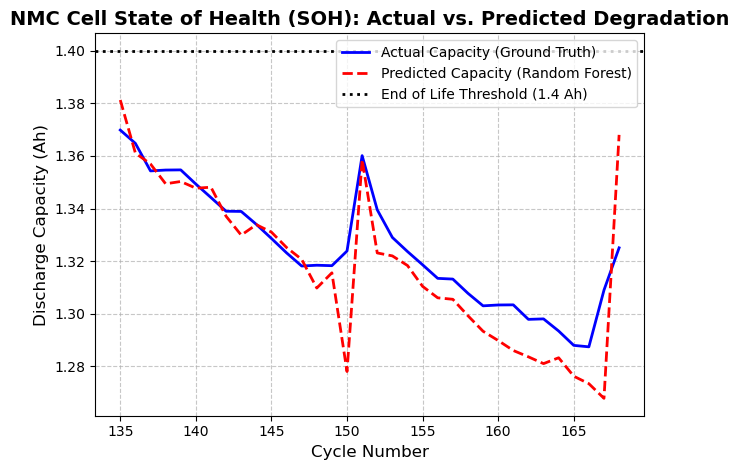

In [38]:
# Plot the actual capacity decay
plt.plot(test_cycles, y_test, label='Actual Capacity (Ground Truth)', color='blue', linewidth=2)

# Plot the model's predicted capacity decay
plt.plot(test_cycles, predictions, label='Predicted Capacity (Random Forest)', color='red', linestyle='--', linewidth=2)

# Add the End of Life (EOL) threshold.
# NASA cells are typically rated for 2.0Ah, and 30% degradation (failure) is around 1.4Ah.
plt.axhline(y=1.4, color='black', linestyle=':', linewidth=2, label='End of Life Threshold (1.4 Ah)')

# Formatting the chart for an industrial R&D audience
plt.xlabel('Cycle Number', fontsize=12)
plt.ylabel('Discharge Capacity (Ah)', fontsize=12)
plt.title('NMC Cell State of Health (SOH): Actual vs. Predicted Degradation', fontsize=14, fontweight='bold')
plt.legend(loc='upper right')
plt.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()